# 11 · From text to MiniGPT: embeddings, attention, Transformer blocks, and a GPT you train yourself

**Source:** *Generative AI Study Notes: From Text to MiniGPT* (Polaris) · **Notes:** `../notes/11_transformer_and_minigpt.md`

**raw text → tokens → embeddings (+ positions) → L Transformer blocks (attention + FFN) → logits → softmax → next token**

In this notebook you will:
1. Check the notes' numbers (attention cost 1.96×, PMI = log 5, cosine similarities, attention weights 0.212 / 0.576 / 0.212).
2. See **why embeddings work**: build word vectors from co-occurrence counts alone, and watch "cat" land next to "dog".
3. Compute **self-attention by hand**, then with causal masking and multiple heads.
4. Build the notes' **MiniGPT** exactly (character-level, 2 blocks, 4 heads, d = 64), train it for 600 steps, and generate text.
5. Run the notes' **student experiments**: remove the causal mask, remove positions, use 1 layer.
6. Play with **temperature and top-k sampling**.

Runs in about 3–4 minutes on a laptop CPU.

In [1]:
%matplotlib inline
import math, time
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
torch.manual_seed(42)

## 1 · Part I recap: why token count matters

Dense attention compares every token with every token: about **T × T** scores per head. If one tokenizer turns a paragraph into 500 tokens and another into 700:

In [2]:
print(f"(700 / 500)^2 = {(700 / 500) ** 2:.2f}  -> almost twice as many attention scores")

# Padding + attention mask: make a rectangular batch, and remember which positions are real
PAD = 0
batch = [[12, 41, 9], [8, 7, 5, 4, 2]]
T = max(len(s) for s in batch)
ids = torch.tensor([s + [PAD] * (T - len(s)) for s in batch])
mask = (ids != PAD).int()
print("padded IDs:\n", ids, "\nattention mask (1 = real, 0 = padding):\n", mask)
print("shape [B, T] =", list(ids.shape))

(700 / 500)^2 = 1.96  -> almost twice as many attention scores
padded IDs:
 tensor([[12, 41,  9,  0,  0],
        [ 8,  7,  5,  4,  2]]) 
attention mask (1 = real, 0 = padding):
 tensor([[1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1]], dtype=torch.int32)
shape [B, T] = [2, 5]


## 2 · Part II: why embeddings work (a statistical view)

### 2a · IDs and one-hot vectors carry no similarity

In [3]:
onehot = torch.eye(5)
cat, dog, car = onehot[0], onehot[1], onehot[2]
print("one-hot: cos(cat, dog) =", F.cosine_similarity(cat, dog, dim=0).item(), " cos(cat, car) =", F.cosine_similarity(cat, car, dim=0).item())
print("-> every pair of different tokens is equally unrelated (orthogonal)")

one-hot: cos(cat, dog) = 0.0  cos(cat, car) = 0.0
-> every pair of different tokens is equally unrelated (orthogonal)


### 2b · Context is evidence: the co-occurrence matrix from the notes
Rows = target words, columns = context words, entries = how often they appear near each other.

In [4]:
contexts = ["pet", "fur", "road", "engine"]
X = np.array([[42, 31, 0, 0],      # cat
              [47, 28, 1, 0],      # dog
              [0, 0, 39, 44]])     # car
words = ["cat", "dog", "car"]
cos = lambda a, b: a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
for i in range(3):
    for j in range(i + 1, 3):
        print(f"cos({words[i]}, {words[j]}) = {cos(X[i], X[j]):.3f}")

print(f"\nPMI(cat, pet) = log(0.001 / (0.01 × 0.02)) = log({0.001 / (0.01 * 0.02):.0f}) = {math.log(5):.3f}  (> 0: together 5× more often than chance)")
a, b = np.array([1, 1]), np.array([0.9, 1.1])
print(f"cos([1,1], [0.9,1.1]): dot = {a @ b:.1f}, cosine = {cos(a, b):.4f}")

cos(cat, dog) = 0.995
cos(cat, car) = 0.000
cos(dog, car) = 0.012

PMI(cat, pet) = log(0.001 / (0.01 × 0.02)) = log(5) = 1.609  (> 0: together 5× more often than chance)
cos([1,1], [0.9,1.1]): dot = 2.0, cosine = 0.9950


### 2c · Meaning without labels: embeddings from counts
Now a bigger experiment. We generate a small corpus of simple sentences, count which words appear near which, take PMI, and compress each word's row to just **2 or 3 numbers** with SVD (X ≈ W·Cᵀ, a "low-dimensional latent factor" model). Nobody tells the model that cat and dog are animals.

corpus: 3000 sentences, vocabulary 53 words

with 2 dimensions:
   cos(cat, dog) = +0.999
   cos(cat, rabbit) = +1.000
   cos(car, truck) = +1.000
   cos(apple, mango) = +1.000
   cos(cat, car) = +0.969
   cos(dog, apple) = +0.154

with 3 dimensions:
   cos(cat, dog) = +1.000
   cos(cat, rabbit) = +1.000
   cos(car, truck) = +1.000
   cos(apple, mango) = +1.000
   cos(cat, car) = +0.056
   cos(dog, apple) = +0.032


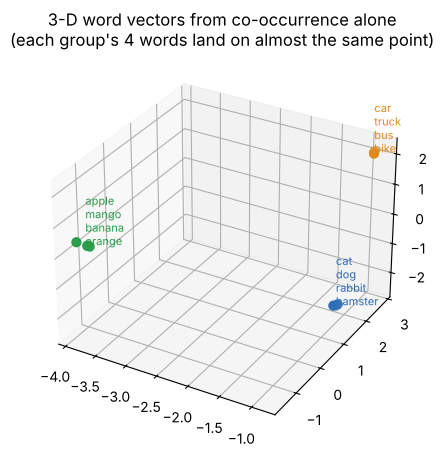

In [5]:
rng = np.random.default_rng(0)
templates = {
    "animal": ["the {w} sleeps on the mat", "my pet {w} has soft fur", "the {w} eats food", "a {w} is a cute pet", "the {w} plays with a ball"],
    "vehicle": ["the {w} drives on the road", "the {w} has an engine", "we park the {w} outside", "the {w} needs fuel", "a fast {w} on the highway"],
    "fruit": ["i eat a sweet {w}", "the {w} is ripe and juicy", "a {w} grows on a tree", "fresh {w} juice", "slice the {w} for lunch"],
}
groups = {"animal": ["cat", "dog", "rabbit", "hamster"], "vehicle": ["car", "truck", "bus", "bike"], "fruit": ["apple", "mango", "banana", "orange"]}
corpus = []
for _ in range(3000):
    g = rng.choice(list(groups)); w = rng.choice(groups[g]); corpus.append(rng.choice(templates[g]).format(w=w).split())
vocab = sorted({t for s in corpus for t in s}); idx = {w: i for i, w in enumerate(vocab)}
C = np.zeros((len(vocab), len(vocab)))
for s in corpus:
    for i, w in enumerate(s):
        for j in range(max(0, i - 3), min(len(s), i + 4)):
            if i != j: C[idx[w], idx[s[j]]] += 1
P = C / C.sum(); pw = P.sum(1, keepdims=True); pc = P.sum(0, keepdims=True)
with np.errstate(divide="ignore"):
    ppmi = np.maximum(np.log(P / (pw * pc)), 0)          # positive PMI
U, Sv, Vt = np.linalg.svd(ppmi)
print(f"corpus: {len(corpus)} sentences, vocabulary {len(vocab)} words")
pairs = [("cat", "dog"), ("cat", "rabbit"), ("car", "truck"), ("apple", "mango"), ("cat", "car"), ("dog", "apple")]
for k in [2, 3]:
    emb = U[:, :k] * Sv[:k]                                # k-dimensional embeddings
    print(f"\nwith {k} dimensions:")
    for a_, b_ in pairs:
        print(f"   cos({a_}, {b_}) = {cos(emb[idx[a_]], emb[idx[b_]]):+.3f}")
emb3 = U[:, :3] * Sv[:3]
fig = plt.figure(figsize=(6, 5)); ax = fig.add_subplot(projection="3d")
for g, col in zip(groups, ["#2f6db5", "#e08a1e", "#2a9d4b"]):
    pts = np.array([emb3[idx[w]] for w in groups[g]])
    ax.scatter(*pts.T, c=col, s=40)
    ax.text(*pts.mean(0), "\n".join(groups[g]), fontsize=8, color=col)
ax.set_title("3-D word vectors from co-occurrence alone\n(each group's 4 words land on almost the same point)"); plt.show()

**What happened:**
- With **3 dimensions**, words from the same group point in the same direction (cosine ≈ 1.0: cat–dog, car–truck, apple–mango) and words from different groups are nearly orthogonal (cat–car ≈ 0.06). **Nobody labelled anything**; the structure came purely from which words appear near which.
- With only **2 dimensions**, three groups don't fit: cat and car are squeezed together (cosine 0.97). Embedding size **d** is a real capacity choice; real models use hundreds to thousands of dimensions.
- Neural embeddings (Word2Vec, a Transformer's embedding table) get the same kind of geometry through **prediction**: vectors that help predict the context are vectors that encode these statistics.

> **Don't over-interpret axes:** an embedding isn't "meaning stored in 3-D". The 3-D plot is a convenience; the model's real space is d_model-dimensional.

## 3 · Part III: attention

### 3a · The notes' example: "The cat sleeps"
Q_cat = [1, 1]; K_The = [1, 0], K_cat = [1, 1], K_sleeps = [0, 1].

In [6]:
q = torch.tensor([1.0, 1.0])
K = torch.tensor([[1.0, 0.0], [1.0, 1.0], [0.0, 1.0]])
scores = K @ q
print("raw scores [The, cat, sleeps]:", scores.tolist())
print("softmax (no scaling)          :", [round(v, 3) for v in torch.softmax(scores, 0).tolist()])
print("softmax(scores / sqrt(d_k=2))  :", [round(v, 3) for v in torch.softmax(scores / math.sqrt(2), 0).tolist()], "<- what the full formula gives")
V = torch.tensor([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])   # toy values: one-hot, so we can read the mixture
print("new 'cat' vector = weights @ V =", [round(v, 3) for v in (torch.softmax(scores, 0) @ V).tolist()])

raw scores [The, cat, sleeps]: [1.0, 2.0, 1.0]
softmax (no scaling)          : [0.212, 0.576, 0.212]
softmax(scores / sqrt(d_k=2))  : [0.248, 0.503, 0.248] <- what the full formula gives
new 'cat' vector = weights @ V = [0.212, 0.576, 0.212]


- The cat query matches its own key best (score 2), so "cat" keeps 57.6% of itself and takes 21.2% from each neighbour: **attention is a weighted mixture, not a choice of one word**.
- The notes' 0.212 / 0.576 / 0.212 is the **unscaled** softmax (the notes say "ignoring scaling for a moment"). With the full formula's ÷√d_k (d_k = 2), the weights are softer: 0.248 / 0.503 / 0.248.

### 3b · Why divide by √d_k?

In [7]:
torch.manual_seed(0)
for d_k in [4, 64, 512]:
    q_, k_ = torch.randn(1000, d_k), torch.randn(1000, 8, d_k)
    raw = (k_ @ q_.unsqueeze(-1)).squeeze(-1)                      # 1000 queries × 8 keys
    top_raw = torch.softmax(raw, -1).max(-1).values.mean().item()
    top_scaled = torch.softmax(raw / math.sqrt(d_k), -1).max(-1).values.mean().item()
    print(f"d_k = {d_k:>3}: spread of raw scores {raw.std().item():5.1f} | average top weight: unscaled {top_raw:.2f}, scaled {top_scaled:.2f}")

d_k =   4: spread of raw scores   2.0 | average top weight: unscaled 0.53, scaled 0.35
d_k =  64: spread of raw scores   8.1 | average top weight: unscaled 0.87, scaled 0.36
d_k = 512: spread of raw scores  22.4 | average top weight: unscaled 0.95, scaled 0.36


Dot products of random d_k-dimensional vectors have a spread of about **√d_k**. Without scaling, at d_k = 512 softmax puts almost all the weight on one key (extremely peaked, so tiny gradients for everyone else). Dividing by √d_k keeps the scores around spread 1 at **any** width.

### 3c · Causal masking (decoder-only models)
Position i may look at positions 0…i only. Implementation: put −∞ on the forbidden scores **before** softmax.

In [8]:
T = 4
torch.manual_seed(1)
scores = torch.randn(T, T)
mask = torch.tril(torch.ones(T, T))
print("visibility (1 = visible):\n", mask.int())
weights = torch.softmax(scores.masked_fill(mask == 0, float("-inf")), dim=-1)
print("attention weights after masking (rows sum to 1, upper triangle exactly 0):\n", weights.numpy().round(3))

visibility (1 = visible):
 tensor([[1, 0, 0, 0],
        [1, 1, 0, 0],
        [1, 1, 1, 0],
        [1, 1, 1, 1]], dtype=torch.int32)
attention weights after masking (rows sum to 1, upper triangle exactly 0):
 [[1.    0.    0.    0.   ]
 [0.625 0.375 0.    0.   ]
 [0.213 0.588 0.199 0.   ]
 [0.088 0.597 0.139 0.176]]


### 3d · Multi-head shapes (the notes' walkthrough, executed)
B = 4, T = 64, d_model = 256, H = 8 heads → d_head = 256 / 8 = 32.

In [9]:
B, T, d_model, H, V_size = 4, 64, 256, 8, 10_000
x = torch.randn(B, T, d_model)
qkv = nn.Linear(d_model, 3 * d_model)
q, k, v = qkv(x).chunk(3, dim=-1)
q = q.view(B, T, H, d_model // H).transpose(1, 2); k = k.view(B, T, H, d_model // H).transpose(1, 2); v = v.view(B, T, H, d_model // H).transpose(1, 2)
att = (q @ k.transpose(-2, -1)) / math.sqrt(d_model // H)
out = (torch.softmax(att, -1) @ v).transpose(1, 2).reshape(B, T, d_model)
logits = nn.Linear(d_model, V_size)(out)
for name, t in [("token IDs", torch.zeros(B, T)), ("embedding output", x), ("Q/K/V per head", q), ("attention scores", att), ("block output", out), ("vocabulary logits", logits)]:
    print(f"{name:<18} {list(t.shape)}")

token IDs          [4, 64]
embedding output   [4, 64, 256]
Q/K/V per head     [4, 8, 64, 32]
attention scores   [4, 8, 64, 64]
block output       [4, 64, 256]
vocabulary logits  [4, 64, 10000]


## 4 · Part IV: build the MiniGPT from the notes

Exactly the notes' classroom design: **character-level** tokenizer, context 64, embedding size 64, 4 heads, 2 blocks, ~600 AdamW updates with batch 32, learning rate 3e-3.

In [10]:
lines = ["the cat sits on the mat.", "the dog sits by the door.", "the bird sings in the tree.",
         "the cat sleeps by the fire.", "the dog runs in the yard."]
rng = np.random.default_rng(0)
text = "\n".join(rng.choice(lines) for _ in range(400)) + "\n"
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}; itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(itos[i] for i in ids)
data = torch.tensor(encode(text), dtype=torch.long)
n_split = int(0.9 * len(data)); train_data, val_data = data[:n_split], data[n_split:]
print(f"corpus: {len(text):,} characters, vocabulary of {len(chars)} characters: {''.join(chars)!r}")
print("encode('the cat') =", encode("the cat"), "-> decode back:", repr(decode(encode("the cat"))))

block_size, batch_size = 64, 32
def get_batch(split="train"):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - block_size - 1, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix]); y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])
    return x, y
xb, yb = get_batch()
print("x shape", list(xb.shape), " y shape", list(yb.shape))
print("x[0][:12] =", repr(decode(xb[0][:12].tolist())), "\ny[0][:12] =", repr(decode(yb[0][:12].tolist())), " <- the same window shifted by one")

corpus: 10,649 characters, vocabulary of 22 characters: '\n .abcdefghilmnoprstuy'
encode('the cat') = [19, 10, 7, 1, 5, 3, 19] -> decode back: 'the cat'
x shape [32, 64]  y shape [32, 64]
x[0][:12] = 'e tree.\nthe ' 
y[0][:12] = ' tree.\nthe d'  <- the same window shifted by one


In [11]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, block_size, causal=True):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads, self.d_head, self.causal = n_heads, d_model // n_heads, causal
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.proj = nn.Linear(d_model, d_model)
        self.register_buffer("mask", torch.tril(torch.ones(block_size, block_size)))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = k.view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.d_head)
        if self.causal:
            scores = scores.masked_fill(self.mask[:T, :T] == 0, float("-inf"))
        weights = torch.softmax(scores, dim=-1)
        out = (weights @ v).transpose(1, 2).contiguous().view(B, T, C)
        return self.proj(out)

class Block(nn.Module):
    def __init__(self, d_model, n_heads, block_size, causal=True):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model); self.attn = CausalSelfAttention(d_model, n_heads, block_size, causal)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model))
    def forward(self, x):
        x = x + self.attn(self.ln1(x))      # communicate (pre-norm, residual)
        x = x + self.ffn(self.ln2(x))       # compute     (pre-norm, residual)
        return x

class MiniGPT(nn.Module):
    def __init__(self, vocab_size, block_size=64, d_model=64, n_heads=4, n_layers=2, causal=True, use_pos=True):
        super().__init__()
        self.block_size, self.use_pos = block_size, use_pos
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(block_size, d_model)
        self.blocks = nn.ModuleList([Block(d_model, n_heads, block_size, causal) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)
    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.token_emb(idx)
        if self.use_pos:
            x = x + self.pos_emb(torch.arange(T))[None, :, :]
        for block in self.blocks:
            x = block(x)
        logits = self.head(self.ln_f(x))
        loss = None if targets is None else F.cross_entropy(logits.view(B * T, -1), targets.view(B * T))
        return logits, loss

@torch.no_grad()
def generate(model, idx, max_new_tokens=100, temperature=1.0, top_k=None):
    for _ in range(max_new_tokens):
        logits, _ = model(idx[:, -model.block_size:])
        logits = logits[:, -1, :] / temperature
        if top_k is not None:
            kth = torch.topk(logits, top_k).values[:, -1, None]
            logits = logits.masked_fill(logits < kth, float("-inf"))
        next_id = torch.multinomial(torch.softmax(logits, dim=-1), num_samples=1)
        idx = torch.cat([idx, next_id], dim=1)
    return idx

torch.manual_seed(42)
model = MiniGPT(vocab_size=len(chars))
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")
print("expected loss at the start (uniform guessing) = ln(vocab) =", round(math.log(len(chars)), 3))
torch.manual_seed(0)
print("\nUNTRAINED model generates:\n" + decode(generate(model, torch.tensor([encode("the ")]), 60)[0].tolist()))

parameters: 107,030
expected loss at the start (uniform guessing) = ln(vocab) = 3.091



UNTRAINED model generates:
the dtnflslpirhous
c..ds yo
utrci.urd.mas th
chsoaupunruiyd rnym

In [12]:
@torch.no_grad()
def val_loss(model, n=20):
    torch.manual_seed(123)
    return np.mean([model(*get_batch("val"))[1].item() for _ in range(n)])

def train(model, steps=600, lr=3e-3, verbose=True, seed=42):
    torch.manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    t0 = time.time()
    for step in range(steps + 1):
        xb, yb = get_batch()
        logits, loss = model(xb, yb)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        if verbose and step % 100 == 0:
            print(f"step {step:>3}: training loss {loss.item():.3f}")
    return time.time() - t0

secs = train(model)
print(f"trained in {secs:.0f} s; validation loss {val_loss(model):.3f}")
torch.manual_seed(0)
print("\nTRAINED model generates:\n" + decode(generate(model, torch.tensor([encode("the ")]), 150)[0].tolist()))

step   0: training loss 3.247


step 100: training loss 0.313


step 200: training loss 0.100


step 300: training loss 0.092


step 400: training loss 0.094


step 500: training loss 0.093


step 600: training loss 0.105
trained in 13 s; validation loss 0.104



TRAINED model generates:
the dor.
the dog sits by the door.
the cat sits on the mat.
the dog sits by the door.
the cat sits by the door.
the cat sleeps by the fire.
the fird.
the 


**What happened:**
- **107,030 parameters**, matching the notes' "~100K-parameter model"; training took about **12 seconds** on a CPU (the notes promise "well under 10 minutes").
- The loss starts at **3.25**, close to ln 22 = 3.09, the value for **uniform guessing** over 22 characters. That's a good sanity check that the model starts knowing nothing.
- It drops to about **0.1** within 200 steps. It can't reach 0, because after "the " the next line is genuinely random (5 possible sentences).
- Before training: random characters. After: real lines from the corpus. Some sampled mistakes remain ("the dor.", "the fird."): the model is sampling, not copying, and a few characters go wrong.

**Shape walkthrough of our forward pass** (the notes' table): idx [B, T] → token_emb [B, T, 64] → after blocks [B, T, 64] → logits [B, T, V] → flattened to [B·T, V] for the loss, because PyTorch's cross-entropy treats **each position as one classification example**. One window of 64 characters therefore gives **64** next-character training targets at once.

## 5 · The notes' student experiments, actually run
Each variant is trained exactly like the baseline (600 steps, same seed). We compare **validation loss** and look at the generated text.

In [13]:
variants = {
    "baseline (2 layers, causal, positions)": dict(),
    "no causal mask": dict(causal=False),
    "no positional embeddings": dict(use_pos=False),
    "1 layer instead of 2": dict(n_layers=1),
    "d_model 128 instead of 64": dict(d_model=128),
}
exp = {}
for name, kw in variants.items():
    torch.manual_seed(42); m = MiniGPT(len(chars), **kw)
    secs = train(m, verbose=False)
    torch.manual_seed(42); xb, yb = get_batch(); train_l = m(xb, yb)[1].item()
    torch.manual_seed(0); sample = decode(generate(m, torch.tensor([encode("the ")]), 60)[0].tolist()).replace("\n", " / ")
    exp[name] = (sum(p.numel() for p in m.parameters()), secs, val_loss(m), sample)
    print(f"{name:<40} params {exp[name][0]:>7,}  time {secs:4.0f}s  val loss {exp[name][2]:.3f}\n    sample: {sample}")

baseline (2 layers, causal, positions)   params 107,030  time   12s  val loss 0.104
    sample: the dor. / the dog sits by the door. / the cat sits on the mat. / the 


no causal mask                           params 107,030  time   11s  val loss 0.003
    sample: the  dn madddd dd. / t. / dd d d d dunnn dd. / the d d dd unad d d. / th


no positional embeddings                 params 107,030  time   13s  val loss 0.099
    sample: the door. / the bird sings in the tree. / the cat sleeps by the fire


1 layer instead of 2                     params  57,046  time    8s  val loss 0.093
    sample: the door. / the bird sings in the tree. / the cat sleeps by the fire


d_model 128 instead of 64                params 410,646  time   24s  val loss 0.091
    sample: the door. / the bird sings in the tree. / the cat sleeps by the fire


**What the experiments showed:**
- **No causal mask: the cheat, caught in the act.** Validation loss fell to **0.003**, far "better" than the baseline. But generation is garbage ("dd d d dunnn"). In training, each position could **see the answer** (the next character) and just copy it. At generation time the future doesn't exist yet, so the trick fails. *A suspiciously low loss in a language model usually means a broken mask.*
- **No positional embeddings: barely any effect here** (0.099 vs 0.104). This is a surprise compared with the notes' prediction ("much harder"). The reason: with a **causal** mask, a position can partly work out where it is from how many tokens it can see, and this corpus is extremely repetitive. For real text with long-range order, positions matter (notebook 09 showed attention without positions can't tell "dog bites man" from "man bites dog").
- **1 layer:** half the parameters (57,046), half the time, and the same loss (0.093) on this tiny corpus. The corpus is too simple to need depth, which is the notes' point: **choose the smallest architecture that clearly learns**.
- **d_model 128:** 3.8× the parameters and 2× the time for only a slightly lower loss (0.091).

The differences between the last four (0.091–0.104) are small, and some of that gap is noise from sampling and training. The **mask** result is the one to remember.

## 6 · Sampling: same model, different text
Softmax gives probabilities; a **decoding rule** picks the token. **Temperature** divides the logits (T < 1 sharpens, T > 1 flattens); **top-k** keeps only the k most likely tokens. No retraining needed.

In [14]:
logits = torch.tensor([2.0, 1.0, 0.5, -1.0])
for temp in [0.5, 1.0, 2.0]:
    print(f"temperature {temp}: probabilities {[round(v, 3) for v in torch.softmax(logits / temp, 0).tolist()]}")
print()
for temp, k in [(0.3, None), (1.0, None), (1.0, 3), (2.0, None)]:
    torch.manual_seed(1)
    out = decode(generate(model, torch.tensor([encode("the ")]), 80, temperature=temp, top_k=k)[0].tolist()).replace("\n", " / ")
    print(f"T = {temp}, top-k = {k}:  {out}")

temperature 0.5: probabilities [0.842, 0.114, 0.042, 0.002]
temperature 1.0: probabilities [0.609, 0.224, 0.136, 0.03]
temperature 2.0: probabilities [0.434, 0.263, 0.205, 0.097]

T = 0.3, top-k = None:  the fire. / the bird sings in the tree. / the dog runs in the yard. / the d. / the dog sits 
T = 1.0, top-k = None:  the cat sits on the mat. / the cat sits on the mat. / the bird sings in the tree. / the do


T = 1.0, top-k = 3:  the door. / the bird sings in the tree. / the dog runs in the yard. / the cat sleeps by th
T = 2.0, top-k = None:  the cat sits on the yard. / tby. / the dog sun the yard. / the cat sits by ts cat. / the dog


- **Low temperature (0.3):** safest choices, very repetitive corpus lines.
- **T = 1 with top-k = 3:** natural-looking and correct.
- **High temperature (2.0):** the distribution flattens (the top token's probability falls from 0.61 to 0.43 in the toy example), so unlikely characters get picked: "the cat sits on the yard", "tby.", "ts cat". It's more "creative" and more wrong.

This is decoding, not training: the **same weights** produced all four texts.

## 7 · From MiniGPT to a production LLM

| MiniGPT (this notebook) | production LLM |
|---|---|
| character vocabulary | BPE / byte-level subwords (notebook 09) |
| d_model = 64, 2 layers, 4 heads | thousands of dims, dozens of layers |
| context 64 | thousands to millions of tokens |
| tiny repetitive corpus | massive curated text and code |
| plain attention, no cache | FlashAttention, GQA/MQA, RoPE, **KV cache** |

The mechanism is identical: embeddings + positions → causal attention → FFN → residuals + LayerNorm → logits → next-token cross-entropy → autoregressive sampling.

## ✅ Check yourself (the notes' subjective questions)
1. One sentence = 28 tokens, d_model = 512. Embedding shape? *([28, 512])* Why does token count matter? *(attention work grows ≈ T²)*
2. Q_cat = [1,1], keys [1,0], [1,1], [0,1]: raw scores? weights? *([1, 2, 1]; ≈ [0.212, 0.576, 0.212] unscaled)*
3. V = 10,000, T = 50, d_model = 256, H = 8: embedding output for one sentence? d_head? *([50, 256]; 32)*
4. What does the causal mask stop? *(each position attending to later tokens, i.e. cheating)*
5. Attention vs FFN in one word each? *(communication; computation)*
6. Why not stack 1,000 layers? *(cost, latency, harder optimisation, diminishing returns or overfitting, memory)*